# **Student Information**

- **Name:** Abdallah Abdelmon'em Ahmad Najeeb
- **Student ID:** 202210159
- **Major:** Business Intelligence and Data Analytics
- **University:** University of Petra
- **Course:** Graduation Project - 307498
- **Supervisor:** Dr. Ayman Mansour

# Jordan CPI: Data Mining Graduation Project

### Purpose
Analyze Jordan’s Consumer Price Index (CPI) by expenditure group and develop a business intelligence view of price trends. A short-term CPI forecast may be included as a predictive analysis component.

### Business question
How can Jordan’s CPI trends help business planners and analysts monitor changes in consumer prices?

### Project stages
1. Load and validate the CPI data.
2. Preprocess the data and document the CPI base-year break.
3. Explore headline and expenditure-group trends.
4. Calculate and rank comparable percentage changes.
5. Build and evaluate a short-term CPI forecast.
6. Present the findings in a BI dashboard and project documentation.

### Course reference
The coding approach follows the pandas and NumPy examples in the [Data Mining Material 2.0 notebook](https://github.com/anajeebb/Data-Mining-Course-Material/blob/main/Data%20Mining%20Material%202.0.ipynb).

## Stage 1 — Load and validate the CPI data

### Purpose
Load the CPI workbook and confirm its sheets, time period, expenditure groups, and data completeness before analysis.

### Business question
Does the provided workbook contain a complete and interpretable monthly CPI series for Jordan?

### Method
Read the `CPI_T1` worksheet with pandas. Check the dates, series labels, numeric values, missing cells, duplicates, and monthly continuity.

### Interpretation
The workbook contains a change in CPI base period between 2019 and 2020. The Department of Statistics explains that it updated the CPI base from 2010 to 2018 in January 2020. We will identify this break before calculating percentage changes.

In [1]:
import pandas as pd
import numpy as np
import requests
import re
from io import BytesIO

# Download the workbook from the project repository
file_url = (
    "https://raw.githubusercontent.com/anajeebb/"
    "Data-Mining-Course-Material/main/"
    "CPI_T1_20261019-235008.xlsx"
)

response = requests.get(file_url, timeout=30)
response.raise_for_status()

# Read the workbook sheets and load the main CPI sheet
workbook_bytes = response.content
excel_file = pd.ExcelFile(BytesIO(workbook_bytes))

print("Workbook sheets:", excel_file.sheet_names)

df_wide = pd.read_excel(
    BytesIO(workbook_bytes),
    sheet_name="CPI_T1"
)

# Clean extra spaces from the column names
df_wide.columns = df_wide.columns.astype(str).str.strip()

print("Main sheet shape:", df_wide.shape)
display(df_wide.head())

Workbook sheets: ['CPI_T1', 'CPI_T1 (TRANSPOSED)']
Main sheet shape: (44, 248)


,Expenditure Groups,2006M01,2006M02,2006M03,2006M04,2006M05,2006M06,2006M07,2006M08,2006M09,...,2025M10,2025M11,2025M12,2026M01,2026M02,2026M03,2026M04,2026M05,2026M06,2026M07
0,0 All Items,78.55,78.12,78.09,79.83,80.77,80.60,80.57,80.79,81.54,...,112.82,112.46,113.22,113.42,113.67,114.53,115.33,115.96,116.13,115.92
1,01 Food and non-Alcoholic Beverages,69.35,68.27,68.28,69.73,72.02,71.29,70.81,71.40,73.46,...,109.03,107.95,108.52,109.00,110.44,112.98,113.33,112.82,111.63,110.72
2,011 Food Items,67.98,66.82,67.13,68.68,70.99,70.56,69.54,70.16,72.37,...,109.03,107.79,108.40,108.94,110.56,113.44,113.91,113.37,111.87,110.83
3,0111 Cereals and Products,69.48,69.62,69.64,69.71,69.74,69.77,69.77,70.52,70.95,...,118.39,118.34,117.89,117.79,117.76,117.85,117.92,118.05,118.11,118.09
4,0112 Meat and Poultry,69.00,63.91,63.83,65.67,72.63,70.69,67.82,67.08,71.26,...,104.95,102.69,106.60,107.63,111.53,115.32,119.22,121.85,117.46,116.81


In [2]:
series_column = df_wide.columns[0]
month_labels = list(df_wide.columns[1:])
series_labels = df_wide[series_column].astype(str).str.strip()

# Check that month labels follow the format YYYY M MM, for example 2006M01
month_pattern = re.compile(r"^\d{4}M(0[1-9]|1[0-2])$")
valid_month_format = all(
    month_pattern.match(str(month)) for month in month_labels
)

# Convert the month labels to monthly periods
if valid_month_format:
    periods = pd.PeriodIndex(
        [f"{str(month)[:4]}-{str(month)[-2:]}" for month in month_labels],
        freq="M"
    )
    expected_periods = pd.period_range(
        start=periods.min(),
        end=periods.max(),
        freq="M"
    )
    months_are_continuous = periods.equals(expected_periods)
else:
    periods = None
    months_are_continuous = False

# Check numeric values, missing values, and duplicates
cpi_values = df_wide.iloc[:, 1:].apply(pd.to_numeric, errors="coerce")
invalid_cells = (
    df_wide.iloc[:, 1:].notna()
    & cpi_values.isna()
).sum().sum()

missing_values = df_wide.iloc[:, 1:].isna().sum().sum()
duplicate_series = series_labels.duplicated().sum()

print("Number of expenditure series:", len(df_wide))
print("Number of monthly observations:", len(month_labels))
print("First month:", month_labels[0])
print("Last month:", month_labels[-1])
print("Month labels have valid format:", valid_month_format)
print("Monthly observations are continuous:", months_are_continuous)
print("Duplicate series labels:", duplicate_series)
print("Missing CPI values:", missing_values)
print("Non-numeric CPI cells:", invalid_cells)

Number of expenditure series: 44
Number of monthly observations: 247
First month: 2006M01
Last month: 2026M07
Month labels have valid format: True
Monthly observations are continuous: True
Duplicate series labels: 0
Missing CPI values: 0
Non-numeric CPI cells: 0


In [3]:
all_items = df_wide.loc[
    series_labels.eq("0 All Items")
].iloc[0]

months_to_check = [
    "2019M12",
    "2020M01",
    "2020M12",
    "2021M01",
    "2026M07"
]

transition_check = pd.DataFrame({
    "Month": months_to_check,
    "All-items CPI index": [
        all_items[month] for month in months_to_check
    ]
})

display(transition_check)

,Month,All-items CPI index
0,2019M12,125.97
1,2020M01,101.57
2,2020M12,101.11
3,2021M01,101.22
4,2026M07,115.92


### Stage 1 findings

The workbook contains 44 CPI series and monthly observations from 2006M01 through 2026M07. The source data has no missing or non-numeric CPI values, and its monthly observations are continuous.

The index base changes from 2010=100 through 2019 to 2018=100 beginning in 2020. Therefore, the apparent difference between the December 2019 and January 2020 index values is a base-period change, not a month-over-month price movement. Percentage-change calculations across that boundary must be excluded.

### Sources
- [CPI workbook in the project repository](https://github.com/anajeebb/Data-Mining-Course-Material/blob/main/CPI_T1_20261019-235008.xlsx)
- [Jordan Department of Statistics explanation of the 2020 CPI base update](https://dosweb.dos.gov.jo/cpi_02_2020/)

## Stage 2 — Reshape and prepare the CPI data

### Purpose
Reshape the CPI workbook into a tidy dataset that is ready for analysis.

### Business question
Can we compare CPI movements across months and expenditure groups without mixing incompatible index bases?

### Method
Create one row per month and series. Extract each series code and name, identify its hierarchy, assign its CPI base period, and calculate month-over-month and year-over-year changes within each base period.

### Interpretation
The CPI percentage changes describe how an index moved over time. They are not category contributions to headline inflation. The workbook does not include expenditure weights needed to calculate contributions.

In [4]:
# Reshape the data so each row represents one month and one CPI series
df_tidy = df_wide.rename(
    columns={series_column: "series_label"}
).melt(
    id_vars="series_label",
    value_vars=month_labels,
    var_name="month_label",
    value_name="cpi_index"
)

# Clean labels and convert CPI values to numbers
df_tidy["series_label"] = df_tidy["series_label"].astype(str).str.strip()
df_tidy["cpi_index"] = pd.to_numeric(
    df_tidy["cpi_index"],
    errors="coerce"
)

# Extract the numeric series code and the readable series name
df_tidy["series_code"] = df_tidy["series_label"].str.extract(
    r"^(\d+)"
)

df_tidy["series_name"] = df_tidy["series_label"].str.replace(
    r"^\d+\s*",
    "",
    regex=True
).str.strip()

# Convert the source month label, such as 2026M07, into a date
df_tidy["month"] = pd.to_datetime(
    df_tidy["month_label"].str.replace("M", "-", regex=False) + "-01"
)

# Add the CPI base period recorded in the source series
df_tidy["base_period"] = np.where(
    df_tidy["month"].dt.year <= 2019,
    "2010=100",
    "2018=100"
)

# Describe the series hierarchy
df_tidy["hierarchy_level"] = np.where(
    df_tidy["series_code"].eq("0"),
    0,
    df_tidy["series_code"].str.len().astype(int) - 1
)

df_tidy["series_type"] = np.select(
    [
        df_tidy["series_code"].eq("0"),
        df_tidy["series_code"].str.len().eq(2)
    ],
    [
        "headline",
        "main_group"
    ],
    default="subgroup"
)

# Sort observations in chronological order within each CPI series
df_tidy = df_tidy.sort_values(
    ["series_code", "month"]
).reset_index(drop=True)

display(df_tidy.head())

,series_label,month_label,cpi_index,series_code,series_name,month,base_period,hierarchy_level,series_type
0,0 All Items,2006M01,78.55,0,All Items,2006-01-01,2010=100,0,headline
1,0 All Items,2006M02,78.12,0,All Items,2006-02-01,2010=100,0,headline
2,0 All Items,2006M03,78.09,0,All Items,2006-03-01,2010=100,0,headline
3,0 All Items,2006M04,79.83,0,All Items,2006-04-01,2010=100,0,headline
4,0 All Items,2006M05,80.77,0,All Items,2006-05-01,2010=100,0,headline


In [5]:
# Group by series and base period so changes do not cross the 2019–2020 break
rate_groups = df_tidy.groupby(
    ["series_code", "base_period"],
    sort=False
)["cpi_index"]

# Calculate month-over-month and year-over-year percentage changes
df_tidy["mom_change_pct"] = (
    rate_groups.pct_change(fill_method=None) * 100
)

df_tidy["yoy_change_pct"] = (
    rate_groups.pct_change(periods=12, fill_method=None) * 100
)

# Show the structure and confirm the transformed data is complete
print("Rows in tidy dataset:", len(df_tidy))
print("Unique CPI series:", df_tidy["series_code"].nunique())
print("Missing CPI values:", df_tidy["cpi_index"].isna().sum())
print(
    "Duplicate month-series rows:",
    df_tidy.duplicated(["month", "series_code"]).sum()
)
print("Missing month-over-month rates:", df_tidy["mom_change_pct"].isna().sum())
print("Missing year-over-year rates:", df_tidy["yoy_change_pct"].isna().sum())

display(
    df_tidy.loc[
        (df_tidy["series_code"] == "0")
        & (df_tidy["month_label"].isin(
            ["2019M12", "2020M01", "2020M12", "2021M01"]
        )),
        [
            "month_label",
            "base_period",
            "cpi_index",
            "mom_change_pct",
            "yoy_change_pct"
        ]
    ]
)

Rows in tidy dataset: 10868
Unique CPI series: 44
Missing CPI values: 0
Duplicate month-series rows: 0
Missing month-over-month rates: 88
Missing year-over-year rates: 1056


,month_label,base_period,cpi_index,mom_change_pct,yoy_change_pct
167,2019M12,2010=100,125.97,0.278618,0.57485
168,2020M01,2018=100,101.57,NaN,NaN
179,2020M12,2018=100,101.11,-0.305660,NaN
180,2021M01,2018=100,101.22,0.108792,-0.34459


### Stage 2 findings

The tidy dataset contains one row for each month and CPI series. The percentage-change calculations are grouped by both series and base period, so January 2020 does not receive a month-over-month or year-over-year rate calculated against the old-base values.

Year-over-year changes for the 2018=100 period begin in January 2021, when a full 12-month comparison within that base period is available. The blank rates at the start of each base-period segment are intentional.

### Data decision
Use `mom_change_pct` for month-over-month comparisons and `yoy_change_pct` for year-over-year comparisons. Keep headline, main-group, and subgroup series separate when ranking results.

## Stage 3 — Explore CPI trends

### Purpose
Explore the all-items CPI trend and compare recent price changes across the 12 main expenditure groups.

### Business question
How have consumer prices changed recently, and which main expenditure groups have the largest increases or decreases?

### Method
Visualize the all-items CPI index and its year-over-year percentage change. Compare expenditure groups using the average CPI for the available months of the latest year against the same months of the previous year.

### Interpretation
The group comparison ranks changes in each group’s CPI index. It does not show each group’s contribution to the all-items CPI because the workbook does not include expenditure weights.

In [6]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

sns.set_theme(style="whitegrid")

# Use the 2018-base all-items series
headline_2018 = df_tidy.loc[
    (df_tidy["series_code"] == "0")
    & (df_tidy["base_period"] == "2018=100")
].sort_values("month")

latest_row = headline_2018.iloc[-1]

print("Latest month:", latest_row["month_label"])
print("All-items CPI index:", round(latest_row["cpi_index"], 2))
print(
    "Month-over-month change:",
    f'{latest_row["mom_change_pct"]:.2f}%'
)
print(
    "Year-over-year change:",
    f'{latest_row["yoy_change_pct"]:.2f}%'
)

Latest month: 2026M07
All-items CPI index: 115.92
Month-over-month change: -0.18%
Year-over-year change: 2.70%


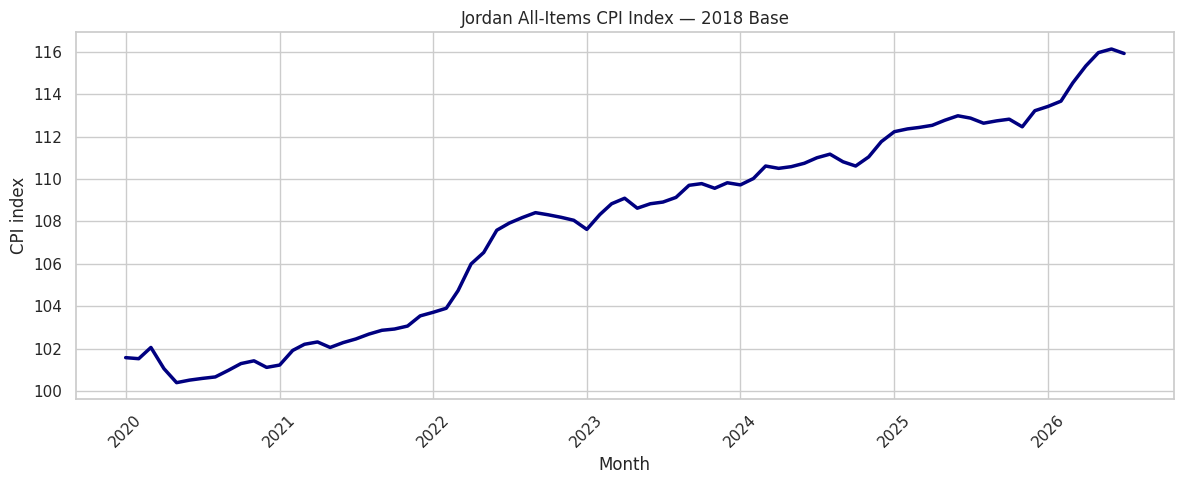

In [7]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=headline_2018,
    x="month",
    y="cpi_index",
    color="navy",
    linewidth=2.5
)

plt.title("Jordan All-Items CPI Index — 2018 Base")
plt.xlabel("Month")
plt.ylabel("CPI index")
plt.gca().xaxis.set_major_locator(mdates.YearLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

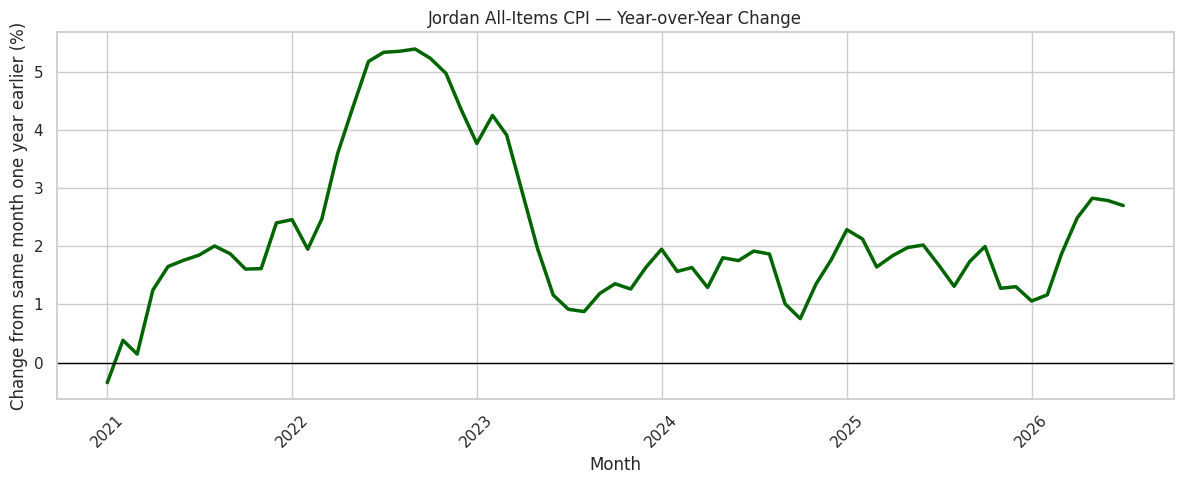

In [8]:
headline_yoy = headline_2018.dropna(
    subset=["yoy_change_pct"]
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=headline_yoy,
    x="month",
    y="yoy_change_pct",
    color="darkgreen",
    linewidth=2.5
)

plt.axhline(0, color="black", linewidth=1)
plt.title("Jordan All-Items CPI — Year-over-Year Change")
plt.xlabel("Month")
plt.ylabel("Change from same month one year earlier (%)")
plt.gca().xaxis.set_major_locator(mdates.YearLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
# Find the latest month available in the 2018-base data
latest_month = df_tidy.loc[
    df_tidy["base_period"] == "2018=100",
    "month"
].max()

latest_year = latest_month.year
latest_month_number = latest_month.month
previous_year = latest_year - 1

# Keep only the 12 main expenditure groups
main_groups = df_tidy.loc[
    (df_tidy["series_type"] == "main_group")
    & (df_tidy["base_period"] == "2018=100")
].copy()

# Average CPI from January through the latest available month
current_ytd = (
    main_groups.loc[
        (main_groups["month"].dt.year == latest_year)
        & (main_groups["month"].dt.month <= latest_month_number)
    ]
    .groupby(["series_code", "series_name"], as_index=False)["cpi_index"]
    .mean()
    .rename(columns={"cpi_index": "current_ytd_average"})
)

previous_ytd = (
    main_groups.loc[
        (main_groups["month"].dt.year == previous_year)
        & (main_groups["month"].dt.month <= latest_month_number)
    ]
    .groupby(["series_code", "series_name"], as_index=False)["cpi_index"]
    .mean()
    .rename(columns={"cpi_index": "previous_ytd_average"})
)

# Calculate the year-to-date percentage change in the average CPI
category_ytd = current_ytd.merge(
    previous_ytd,
    on=["series_code", "series_name"],
    how="inner",
    validate="one_to_one"
)

category_ytd["ytd_change_pct"] = (
    category_ytd["current_ytd_average"]
    / category_ytd["previous_ytd_average"]
    - 1
) * 100

category_ytd = category_ytd.sort_values(
    "ytd_change_pct",
    ascending=False
).reset_index(drop=True)

print(
    f"Comparison: January–{latest_month.strftime('%B')} "
    f"{latest_year} versus the same months in {previous_year}"
)

display(
    category_ytd[
        [
            "series_code",
            "series_name",
            "ytd_change_pct"
        ]
    ].round(2)
)

Comparison: January–July 2026 versus the same months in 2025


,series_code,series_name,ytd_change_pct
0,02,Alcohol and Tobacco and Cigarettes,3.98
1,12,Other Goods and Services,3.56
2,07,Transportation,3.28
3,04,housing,3.16
4,10,Education,2.76
5,08,Communication,1.97
6,09,Culture and Recreation,1.79
7,01,Food and non-Alcoholic Beverages,1.00
8,06,health,0.45
9,11,Restaurants and Hotels,0.43


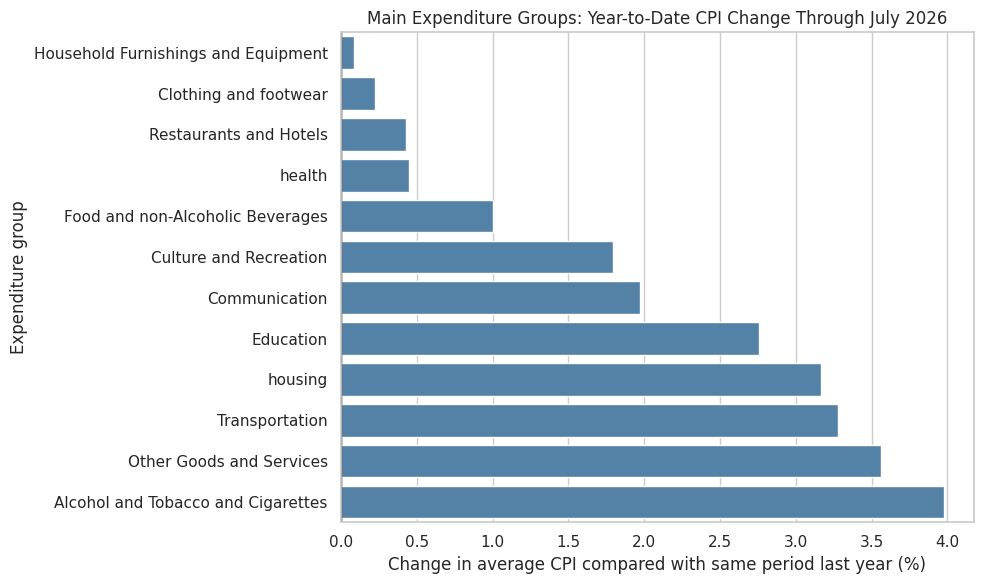

In [10]:
category_plot = category_ytd.sort_values(
    "ytd_change_pct",
    ascending=True
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_plot,
    x="ytd_change_pct",
    y="series_name",
    color="steelblue"
)

plt.axvline(0, color="black", linewidth=1)
plt.title(
    f"Main Expenditure Groups: Year-to-Date CPI Change "
    f"Through {latest_month.strftime('%B %Y')}"
)
plt.xlabel("Change in average CPI compared with same period last year (%)")
plt.ylabel("Expenditure group")
plt.tight_layout()
plt.show()

### Stage 3 findings

The all-items CPI index increased over the 2018-base period, although its year-over-year rate varied over time. In July 2026, the all-items index was 115.92, with a year-over-year increase of 2.70%.

For January–July 2026 compared with the same months of 2025, Alcohol and Tobacco and Cigarettes had the largest increase among the main groups (3.98%), followed by Other Goods and Services (3.56%) and Transportation (3.28%). Household Furnishings and Equipment had the smallest increase (0.09%).

These rankings compare changes in group CPI indices. They do not measure each group’s contribution to all-items inflation, because the workbook does not include expenditure weights. The patterns support monitoring broad price movements; they do not establish the causes or business impact of those movements.

## Stage 4 — Compare inflation rates across expenditure groups

### Purpose
Compare year-to-date CPI changes with the latest month-over-month and year-over-year rates.

### Business question
Which main expenditure groups have higher or lower recent CPI changes, and are their latest monthly movements consistent with their year-to-date patterns?

### Method
For the all-items series and 12 main expenditure groups, compare average CPI from January through the latest available month with the same months of the previous year. Add the latest month-over-month and year-over-year changes.

### Interpretation
These calculations show changes in CPI indices. They do not measure category contributions to headline inflation or explain the causes of price changes.

In [11]:
# Use headline and main-group series from the 2018-base period
analysis_series = df_tidy.loc[
    (df_tidy["base_period"] == "2018=100")
    & (df_tidy["series_type"].isin(["headline", "main_group"]))
].copy()

latest_month = analysis_series["month"].max()
latest_year = latest_month.year
latest_month_number = latest_month.month
previous_year = latest_year - 1

# Average CPI from January through the latest available month
current_period = analysis_series.loc[
    (analysis_series["month"].dt.year == latest_year)
    & (analysis_series["month"].dt.month <= latest_month_number)
].groupby(
    ["series_code", "series_name", "series_type"],
    as_index=False
)["cpi_index"].mean().rename(
    columns={"cpi_index": "current_period_average"}
)

previous_period = analysis_series.loc[
    (analysis_series["month"].dt.year == previous_year)
    & (analysis_series["month"].dt.month <= latest_month_number)
].groupby(
    ["series_code", "series_name", "series_type"],
    as_index=False
)["cpi_index"].mean().rename(
    columns={"cpi_index": "previous_period_average"}
)

period_comparison = current_period.merge(
    previous_period,
    on=["series_code", "series_name", "series_type"],
    how="inner",
    validate="one_to_one"
)

period_comparison["ytd_change_pct"] = (
    period_comparison["current_period_average"]
    / period_comparison["previous_period_average"]
    - 1
) * 100

# Add the latest available monthly rates
latest_rates = analysis_series.loc[
    analysis_series["month"] == latest_month,
    [
        "series_code",
        "mom_change_pct",
        "yoy_change_pct"
    ]
]

period_comparison = period_comparison.merge(
    latest_rates,
    on="series_code",
    how="left",
    validate="one_to_one"
)

# Display the all-items result separately from main-group rankings
headline_comparison = period_comparison.loc[
    period_comparison["series_type"] == "headline"
]

main_group_comparison = (
    period_comparison.loc[
        period_comparison["series_type"] == "main_group"
    ]
    .sort_values("ytd_change_pct", ascending=False)
    .reset_index(drop=True)
)

print(
    f"All-items change, January–{latest_month.strftime('%B')} "
    f"{latest_year} versus the same months in {previous_year}: "
    f'{headline_comparison["ytd_change_pct"].iloc[0]:.2f}%'
)

display(
    main_group_comparison[
        [
            "series_code",
            "series_name",
            "ytd_change_pct",
            "yoy_change_pct",
            "mom_change_pct"
        ]
    ].round(2)
)

All-items change, January–July 2026 versus the same months in 2025: 2.13%


,series_code,series_name,ytd_change_pct,yoy_change_pct,mom_change_pct
0,02,Alcohol and Tobacco and Cigarettes,3.98,3.98,0.00
1,12,Other Goods and Services,3.56,2.82,-0.20
2,07,Transportation,3.28,6.77,0.00
3,04,housing,3.16,3.86,0.01
4,10,Education,2.76,2.77,0.00
5,08,Communication,1.97,1.03,0.75
6,09,Culture and Recreation,1.79,2.72,-0.02
7,01,Food and non-Alcoholic Beverages,1.00,0.70,-0.82
8,06,health,0.45,0.42,0.07
9,11,Restaurants and Hotels,0.43,0.32,0.18


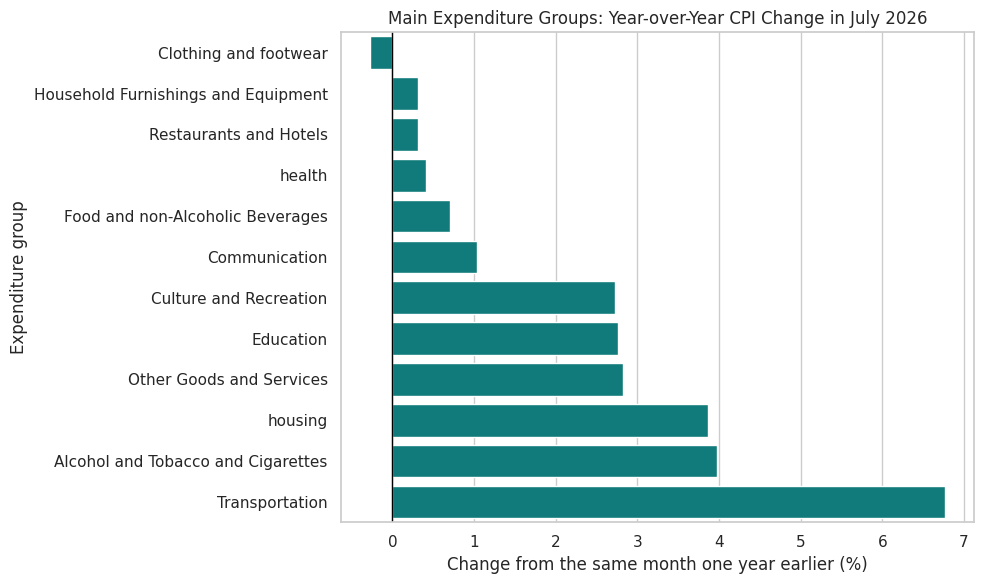

In [12]:
latest_yoy_plot = main_group_comparison.sort_values(
    "yoy_change_pct",
    ascending=True
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=latest_yoy_plot,
    x="yoy_change_pct",
    y="series_name",
    color="darkcyan"
)

plt.axvline(0, color="black", linewidth=1)
plt.title(
    f"Main Expenditure Groups: Year-over-Year CPI Change "
    f"in {latest_month.strftime('%B %Y')}"
)
plt.xlabel("Change from the same month one year earlier (%)")
plt.ylabel("Expenditure group")
plt.tight_layout()
plt.show()

### Stage 4 findings

Through July 2026, the all-items CPI average was 2.13% higher than for January–July 2025. Among the main expenditure groups, Alcohol and Tobacco and Cigarettes had the largest year-to-date increase (3.98%), while Household Furnishings and Equipment had the smallest (0.09%).

The latest monthly movements differ across groups. Food and non-Alcoholic Beverages decreased by 0.82% month over month in July, while Communication increased by 0.75%. These monthly rates provide a short-term snapshot and should be interpreted alongside the year-to-date and year-over-year comparisons.

The group rates describe CPI index movements, not contributions to headline inflation. Expenditure weights would be required to calculate contributions.

## Stage 5 — Forecast the all-items CPI

### Purpose
Build and evaluate a six-month forecast of Jordan’s all-items CPI.

### Business question
How well can a simple model forecast the all-items CPI six months ahead compared with basic forecasting benchmarks?

### Method
Use linear regression with a time trend and month-of-year indicators. Evaluate it against a latest-value baseline and a seasonal-naive baseline using rolling forecast origins from January 2025 onward. Train each forecast only on data available before its forecast origin.

### Evaluation
Compare mean absolute error (MAE), root mean squared error (RMSE), and mean absolute percentage error (MAPE). Lower values indicate smaller errors. MAPE is an error percentage; it should not be described as model accuracy.

### Limitation
The provided workbook ends in July 2026. Any final forecast from this workbook must be labeled as based on information available through July 2026. Refresh the source before presenting it as a current forecast.

In [13]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Select the 2018-base all-items CPI series
model_data = df_tidy.loc[
    (df_tidy["series_code"] == "0")
    & (df_tidy["base_period"] == "2018=100"),
    ["month", "month_label", "cpi_index"]
].sort_values("month").reset_index(drop=True)

# Create a time trend feature
model_data["time_index"] = np.arange(len(model_data))

# Create month-of-year indicator features
month_features = pd.get_dummies(
    model_data["month"].dt.month,
    prefix="month",
    drop_first=True,
    dtype=int
)

# Prepare feature sets for the two regression models
X_trend = model_data[["time_index"]]

X_trend_month = pd.concat(
    [
        model_data[["time_index"]],
        month_features
    ],
    axis=1
)

y = model_data["cpi_index"].to_numpy()

# Start the rolling evaluation in January 2025
validation_start = model_data.index[
    model_data["month"].eq(pd.Timestamp("2025-01-01"))
][0]

forecast_horizon = 6

print("Training data begins:", model_data.loc[0, "month_label"])
print(
    "First forecast origin:",
    model_data.loc[validation_start, "month_label"]
)
print("Last observed month:", model_data.iloc[-1]["month_label"])
print("Forecast horizon:", forecast_horizon, "months")

Training data begins: 2020M01
First forecast origin: 2025M01
Last observed month: 2026M07
Forecast horizon: 6 months


In [14]:
prediction_rows = []

# At each origin, forecast six months ahead using only earlier observations
for origin in range(
    validation_start,
    len(model_data) - forecast_horizon + 1
):
    target_index = origin + forecast_horizon - 1

    y_train = y[:origin]
    actual_value = y[target_index]

    # Baseline 1: carry forward the latest observed CPI
    latest_value_forecast = y[origin - 1]

    # Baseline 2: use the CPI from the same month one year earlier
    seasonal_naive_forecast = y[target_index - 12]

    # Model 1: linear regression with time trend
    trend_model = LinearRegression()
    trend_model.fit(X_trend.iloc[:origin], y_train)
    trend_forecast = trend_model.predict(
        X_trend.iloc[[target_index]]
    )[0]

    # Model 2: linear regression with time trend and month indicators
    trend_month_model = LinearRegression()
    trend_month_model.fit(
        X_trend_month.iloc[:origin],
        y_train
    )
    trend_month_forecast = trend_month_model.predict(
        X_trend_month.iloc[[target_index]]
    )[0]

    prediction_rows.append({
        "forecast_origin": model_data.loc[origin, "month_label"],
        "target_month": model_data.loc[target_index, "month_label"],
        "actual": actual_value,
        "latest_value": latest_value_forecast,
        "seasonal_naive": seasonal_naive_forecast,
        "linear_trend": trend_forecast,
        "trend_plus_month": trend_month_forecast
    })

forecast_results = pd.DataFrame(prediction_rows)

display(forecast_results.head())
print("Number of evaluated six-month forecasts:", len(forecast_results))

,forecast_origin,target_month,actual,latest_value,seasonal_naive,linear_trend,trend_plus_month
0,2025M01,2025M06,112.98,111.76,110.74,113.585922,113.727750
1,2025M02,2025M07,112.87,112.23,111.00,113.777913,113.897412
2,2025M03,2025M08,112.63,112.36,111.17,113.965183,114.059778
3,2025M04,2025M09,112.74,112.43,110.81,114.143845,114.195789
4,2025M05,2025M10,112.82,112.53,110.61,114.316652,114.182600


Number of evaluated six-month forecasts: 14


In [15]:
forecast_columns = {
    "Latest-value baseline": "latest_value",
    "Seasonal-naive baseline": "seasonal_naive",
    "Linear trend": "linear_trend",
    "Trend plus month indicators": "trend_plus_month"
}

metric_rows = []

for model_name, forecast_column in forecast_columns.items():
    actual_values = forecast_results["actual"]
    predicted_values = forecast_results[forecast_column]

    mae = mean_absolute_error(actual_values, predicted_values)
    rmse = np.sqrt(
        mean_squared_error(actual_values, predicted_values)
    )
    mape = (
        np.abs(
            (actual_values - predicted_values) / actual_values
        ).mean()
        * 100
    )

    metric_rows.append({
        "model": model_name,
        "MAE_index_points": mae,
        "RMSE_index_points": rmse,
        "MAPE_percent_error": mape
    })

forecast_metrics = (
    pd.DataFrame(metric_rows)
    .sort_values("MAE_index_points")
    .reset_index(drop=True)
)

display(forecast_metrics.round(3))

,model,MAE_index_points,RMSE_index_points,MAPE_percent_error
0,Trend plus month indicators,1.008,1.117,0.889
1,Linear trend,1.019,1.147,0.899
2,Latest-value baseline,1.291,1.694,1.123
3,Seasonal-naive baseline,2.099,2.207,1.837


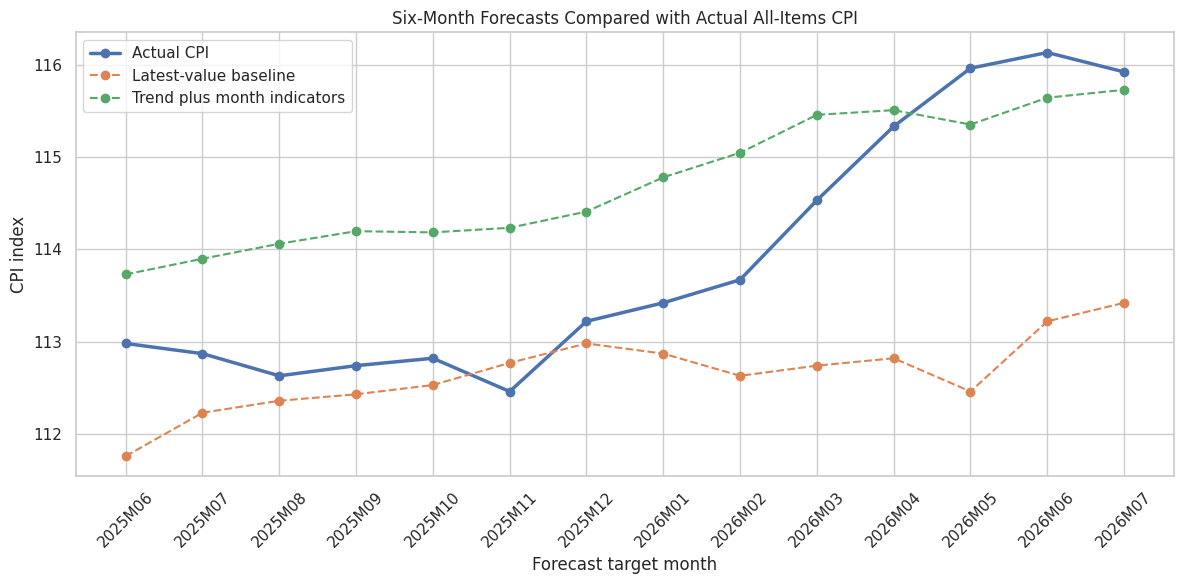

In [16]:
plt.figure(figsize=(12, 6))

plt.plot(
    forecast_results["target_month"],
    forecast_results["actual"],
    marker="o",
    linewidth=2.5,
    label="Actual CPI"
)

plt.plot(
    forecast_results["target_month"],
    forecast_results["latest_value"],
    marker="o",
    linestyle="--",
    label="Latest-value baseline"
)

plt.plot(
    forecast_results["target_month"],
    forecast_results["trend_plus_month"],
    marker="o",
    linestyle="--",
    label="Trend plus month indicators"
)

plt.title("Six-Month Forecasts Compared with Actual All-Items CPI")
plt.xlabel("Forecast target month")
plt.ylabel("CPI index")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [17]:
# Fit the selected trend-plus-month model on all observations
final_model = LinearRegression()
final_model.fit(X_trend_month, y)

# Forecast six months after the latest month in the provided workbook
last_month = model_data["month"].iloc[-1]
future_month = last_month + pd.DateOffset(months=forecast_horizon)
future_time_index = len(model_data) - 1 + forecast_horizon

# Create the future month indicator features
future_features = pd.DataFrame({
    "time_index": [future_time_index]
})

for column in X_trend_month.columns:
    if column != "time_index":
        month_number = int(column.replace("month_", ""))
        future_features[column] = int(
            future_month.month == month_number
        )

# Keep feature columns in the same order as the training data
future_features = future_features[X_trend_month.columns]

future_forecast = final_model.predict(future_features)[0]

print("Data available through:", last_month.strftime("%B %Y"))
print("Six-month forecast target:", future_month.strftime("%B %Y"))
print("Forecast all-items CPI:", round(future_forecast, 2))

Data available through: July 2026
Six-month forecast target: January 2027
Forecast all-items CPI: 116.69


### Stage 5 findings

The trend-plus-month-indicators regression had the lowest error among the four methods tested for six-month-ahead forecasts. Across 14 rolling forecast origins, it recorded an MAE of 1.008 CPI index points, an RMSE of 1.117 points, and a MAPE of 0.889%. The latest-value baseline recorded an MAE of 1.291 points, an RMSE of 1.694 points, and a MAPE of 1.123%.

The improvement over the latest-value baseline suggests that the tested trend and month indicators may be useful for this forecasting task. The improvement over the linear-trend model was small, and the evaluation contains only 14 forecast cases. The results therefore identify the best performer among the methods tested; they do not establish that it will consistently outperform other models.

Fitted to the full workbook, the selected model estimates an all-items CPI index of 116.69 for January 2027. This is a model estimate based on data through July 2026, not an official projection or a current-data forecast.